In [1]:
%%capture --no-stderr
%pip install -q -U langgraph langchain-core groq

In [2]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [3]:
#1) LLM helper — usando Groq com openai/gpt-oss-120b

In [4]:
from groq import Groq
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, BaseMessage

client = Groq()

def _lc_messages_to_groq(messages: list[BaseMessage]) -> list[dict]:
    """Converte mensagens LangChain -> formato Groq (role/content)."""
    groq_msgs = []
    for m in messages:
        if isinstance(m, SystemMessage):
            role = "system"
        elif isinstance(m, HumanMessage):
            role = "user"
        elif isinstance(m, AIMessage):
            role = "assistant"
        else:
            # fallback: tenta usar o 'type' do LangChain (human/ai/system)
            role = getattr(m, "type", "user")
        groq_msgs.append({"role": role, "content": m.content})
    return groq_msgs

def groq_chat_streaming(
    messages: list[BaseMessage],
    model: str = "openai/gpt-oss-120b",
    temperature: float = 1.0,
    max_completion_tokens: int = 1024,
    top_p: float = 1.0,
    reasoning_effort: str = "medium",
) -> AIMessage:
    """Chama Groq em streaming e devolve uma AIMessage (Computação Quântica)."""
    completion = client.chat.completions.create(
        model=model,
        messages=_lc_messages_to_groq(messages),
        temperature=temperature,
        max_completion_tokens=max_completion_tokens,
        top_p=top_p,
        reasoning_effort=reasoning_effort,
        stream=True,
        stop=None,
    )

    parts = []
    for chunk in completion:
        delta = chunk.choices[0].delta.content or ""
        parts.append(delta)

    text = "".join(parts).strip()
    return AIMessage(content=text, name="Eugenio-JR_bot")

# Teste rápido (pode comentar se quiser)
msgs = [
    SystemMessage(content="Você é um assistente didático em PT-BR."),
    HumanMessage(content="Em 1 frase: o que é Computação Quântica?", name="Eugenio JR"),
]
resp = groq_chat_streaming(msgs, max_completion_tokens=200)
resp.pretty_print()

================================== Ai Message ==================================
Name: Eugenio-JR_bot

Computação quântica é um campo da ciência que usa princípios da mecânica quântica — como superposição e entrelaçamento — para processar informação de forma exponencialmente mais poderosa que os computadores clássicos.


In [5]:
#2) Schema de Estado: o “contrato” do seu grafo:  quais chaves existem e que tipo de dados cada uma guarda
#2.1) TypedDict: simples e muito usado

In [6]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class Estado_Socio(TypedDict):
    nome: str
    proximo_passo: str

def montar_proximo_passo(state: Estado_Socio) -> dict:
    # Comentário: note que o node só precisa devolver as chaves que quer atualizar.
    return {"proximo_passo": f"{state['nome']}, vamos criar uma startup com foco em engenharia de IA."}
builder = StateGraph(Estado_Socio)
builder.add_node("proximo_passo", montar_proximo_passo)
builder.add_edge(START, "proximo_passo")
builder.add_edge("proximo_passo", END)

grafo = builder.compile()
#nome = "Eugenio JR"
#grafo.invoke({"nome": nome, "proximo_passo": ""})

grafo.invoke({"nome": "Eugenio-JR", "proximo_passo": ""})

{'nome': 'Eugenio-JR',
 'proximo_passo': 'Eugenio-JR, vamos criar uma startup com foco em engenharia de IA.'}

In [7]:
#2.2) Restrições com Literal
#Quando você quer “travar” um conjunto de valores possíveis (por exemplo, o estágio do aluno no curso).

In [8]:
from typing import Literal

class EstadoProgresso(TypedDict):
    nome: str
    etapa: Literal["aquecimento", "pratica", "revisao"]

def avancar_etapa(state: EstadoProgresso) -> dict:
    # Um fluxo super simples só pra mostrar a ideia.
    if state["etapa"] == "aquecimento":
        return {"etapa": "pratica"}
    if state["etapa"] == "pratica":
        return {"etapa": "revisao"}
    return {"etapa": "revisao"}

builder = StateGraph(EstadoProgresso)
builder.add_node("avancar", avancar_etapa)
builder.add_edge(START, "avancar")
builder.add_edge("avancar", END)
grafo_etapas = builder.compile()

grafo_etapas.invoke({"nome": "Eugenio JR", "etapa": "aquecimento"})
#grafo_etapas.invoke({"nome": "Eugenio JR", "etapa": "pratica"})
#grafo_etapas.invoke({"nome": "Eugenio JR", "etapa": "revisao"})

{'nome': 'Eugenio JR', 'etapa': 'pratica'}

In [9]:
#2.3) dataclass como estado: objetos com atributos
#dentro do node, você acessa atributos com state.campo

In [10]:
from dataclasses import dataclass

@dataclass
class Estado_Startup:
    nome: str
    resumo: str = ""
# função gerar resumo
def gerar_resumo(state: Estado_Startup) -> dict:
    # Acesso via atributo
    return {"resumo": f"Feedback {state.nome}: Hoje tivemos uma boa consultoria sobre a abertura da nossa Startup."}

builder = StateGraph(Estado_Startup)
builder.add_node("resumo", gerar_resumo)
builder.add_edge(START, "resumo")
builder.add_edge("resumo", END)

grafo_dc = builder.compile()

grafo_dc.invoke(Estado_Startup(nome="Eugenio JR"))
#nome = "Eugenio JR"
#grafo_dc.invoke(Estado_Startup(nome=nome))

{'nome': 'Eugenio JR',
 'resumo': 'Feedback Eugenio JR: Hoje tivemos uma boa consultoria sobre a abertura da nossa Startup.'}

In [11]:
#3) Reducers de Estado: como evitar “briga” de updates
#3.1) O comportamento padrão (sobrescrita) e o erro de conflito

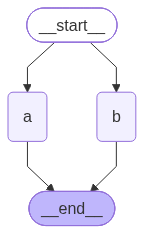

❌ Deu conflito de update (como esperado), tenta processar A e B ao mesmo tempo.
Mensagem do erro: At key 'foo': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_CONCURRENT_GRAPH_UPDATE


In [12]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.errors import InvalidUpdateError
from IPython.display import Image, display
class EstadoBugado(TypedDict):
    foo: int

def node_a(state: EstadoBugado) -> dict:
    return {"foo": state["foo"] + 1}

def node_b(state: EstadoBugado) -> dict:
    return {"foo": state["foo"] + 10}

builder = StateGraph(EstadoBugado)
builder.add_node("a", node_a)
builder.add_node("b", node_b)

# Os dois nós rodam "em paralelo" depois do START:
builder.add_edge(START, "a")
builder.add_edge(START, "b")
builder.add_edge("a", END)
builder.add_edge("b", END)

g = builder.compile()
display(Image(g.get_graph().draw_mermaid_png()))
try:
    g.invoke({"foo": 1})
except InvalidUpdateError as e:
    print("❌ Deu conflito de update (como esperado), tenta processar A e B ao mesmo tempo.")
    print("Mensagem do erro:", e)

In [13]:
#3.2) Resolvendo com reducer (ex.: listas + operator.add)
#O padrão mais comum: sua chave vira lista e você usa add (concatenação) como reducer.
#Ou seja: cada nó devolve uma lista e o reducer junta tudo.

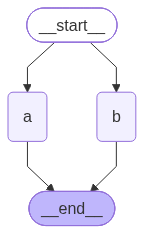

{'tarefas': ['Reunião 3', 'Criar grafos com reducers']}

In [14]:
from operator import add
from typing_extensions import Annotated
from IPython.display import Image, display
class EstadoComReducer(TypedDict):
    # Annotated[TIPO, REDUCER]
    tarefas: Annotated[list[str], add]

def fazer_tarefas_a(state: EstadoComReducer) -> dict:
    return {"tarefas": ["Reunião 3"]}

def fazer_tarefas_b(state: EstadoComReducer) -> dict:
    return {"tarefas": ["Criar grafos com reducers"]}
# vc escolhe a ordem 
builder = StateGraph(EstadoComReducer)
builder.add_node("a", fazer_tarefas_a)
builder.add_node("b", fazer_tarefas_b)

builder.add_edge(START, "a")
builder.add_edge(START, "b")
builder.add_edge("a", END)
builder.add_edge("b", END)

g_ok = builder.compile()
display(Image(g_ok.get_graph().draw_mermaid_png()))
g_ok.invoke({"tarefas": []})


In [15]:
#Múltiplos Schemas: estado público vs. estado privado + input/output
#4.1) Estado privado (interno) no grafo

In [15]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class EstadoPublico(TypedDict):
    erro: int

class EstadoPrivado(EstadoPublico):
    segredo_interno: str

def add_segredo(state: EstadoPublico) -> dict:
    # Isso só existe internamente (no schema privado).
    return {"segredo_interno": f"debug(erro={state['erro']})"}

def soma_erro(state: EstadoPrivado) -> dict:
    # Aqui a gente "enxerga" o segredo_interno porque este nó roda com EstadoPrivado
    return {"erro": state["erro"] + 1}

builder = StateGraph(EstadoPrivado)  # o grafo inteiro usa o estado mais completo
builder.add_node("segredo", add_segredo)
builder.add_node("soma", soma_erro)

builder.add_edge(START, "segredo")
builder.add_edge("segredo", "soma")
builder.add_edge("soma", END)

grafo_privado = builder.compile()
grafo_privado.invoke({"erro": 3})

{'erro': 4, 'segredo_interno': 'debug(erro=3)'}

In [16]:
#4.2) Schema de input e output (entrada/saída controlada)
#Aqui é onde fica elegante para produto/curso:

#input: só o que o aluno precisa mandar
#output: só o que você quer devolver (sem “vazar” estado interno)

In [17]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class EstadoGeral(TypedDict):
    pergunta: str
    resposta: str
    # estado extra interno:
    rastreio: str

class EstadoEntrada(TypedDict):
    pergunta: str

class EstadoSaida(TypedDict):
    resposta: str

def responder(state: EstadoGeral) -> dict:
    # Simulando um processamento (aqui não chamamos LLM ainda).
    return {
        "rastreio": "trace_id=abc123 (interno)",
        "resposta": f"Você perguntou: '{state['pergunta']}'. Minha resposta: depende do seu objetivo, Eugenio JR 😄"
    }

builder = StateGraph(EstadoGeral, input=EstadoEntrada, output=EstadoSaida)
builder.add_node("responder", responder)
builder.add_edge(START, "responder")
builder.add_edge("responder", END)

grafo_io = builder.compile()
#pergunta = Quando usar LanGGraph?
# Note que o invoke aceita só a entrada...
#out = grafo_io.invoke({"pergunta": pergunta})
pergunta = Quando usar LanGGraph?
# Note que o invoke aceita só a entrada...
out = grafo_io.invoke({"pergunta": "Quando usar LanGGraph?"})
out
out

Object `LanGGraph` not found.


C:\Users\eugen\AppData\Local\Temp\ipykernel_13296\1163728661.py:23: LangGraphDeprecatedSinceV05: `input` is deprecated and will be removed. Please use `input_schema` instead. Deprecated in LangGraph V0.5 to be removed in V2.0.
  builder = StateGraph(EstadoGeral, input=EstadoEntrada, output=EstadoSaida)
C:\Users\eugen\AppData\Local\Temp\ipykernel_13296\1163728661.py:23: LangGraphDeprecatedSinceV05: `output` is deprecated and will be removed. Please use `output_schema` instead. Deprecated in LangGraph V0.5 to be removed in V2.0.
  builder = StateGraph(EstadoGeral, input=EstadoEntrada, output=EstadoSaida)


{'resposta': "Você perguntou: 'Quando usar LanGGraph?'. Minha resposta: depende do seu objetivo, Eugenio JR 😄"}

In [18]:
#5) Mensagens como Estado (MessagesState) com Groq
#5.1) Mensagens iniciais

In [19]:
from langchain_core.messages import AIMessage, HumanMessage
from pprint import pprint

messages = [
    AIMessage("Você disse que está montando um curso sobre LangGraph, né?", name="Eugenio_Bot"),
    HumanMessage("Sim! Mas eu ainda travo em reducers e schemas. Me ajuda com um exemplo prático com código em python?", name="Eugenio JR"),
]

for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Eugenio_Bot

Você disse que está montando um curso sobre LangGraph, né?
================================ Human Message =================================
Name: Eugenio JR

Sim! Mas eu ainda travo em reducers e schemas. Me ajuda com um exemplo prático com código em python?


In [20]:
#CONTINUAÇÃO
#5.2) Um grafo mínimo: 1 nó que chama o LLM (Groq)


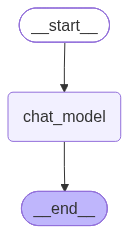

In [21]:
from IPython.display import Image, display
from langgraph.graph import MessagesState
from langgraph.graph import StateGraph, START, END

def chat_model_node(state: MessagesState):
    # Chamando Groq com o histórico completo
    ai = groq_chat_streaming(
        [SystemMessage(content="Você é um tutor didático em PT-BR, com exemplos práticos e com dódigos em python de LangGraph .")] 
        + state["messages"],
        max_completion_tokens=400,
    )
    return {"messages": [ai]}

builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph_chat = builder.compile()

display(Image(graph_chat.get_graph().draw_mermaid_png()))

In [105]:
out = graph_chat.invoke({"messages": messages})
out["messages"][-1].pretty_print()

================================== Ai Message ==================================
Name: Eugenio-JR_bot

## 🎓 LangGraph: Reducers e Schemas – um exemplo “do‑zero”

A seguir vamos montar **um fluxo simples de coleta de dados** usando a biblioteca **LangGraph** (v0.0.x).  
O objetivo do exemplo é:

1. **Definir um *schema*** que descreve o estado que a nossa máquina de fluxo vai manter.  
2. **Criar *reducers*** – funções puras que recebem o estado atual + um input e retornam o novo estado.  
3. **Montar o grafo** (nós → transições) usando `StateGraph`.  
4. **Executar o grafo** e observar como o estado evolui passo a passo.

> **⚡️ Dica rápida:**  
> - *Schema* = “forma” dos dados (usamos `pydantic.BaseModel`).  
> - *Reducer* = “como o estado muda” (sempre retorna um novo objeto, nunca muta o anterior).

---

## 1️⃣ Preparação do ambiente

```bash
# Crie um ambiente virtual (opcional, mas recomendado)
python -m venv .venv
source .venv/bin/activate   # Windows: .venv\Scripts\activate

# I

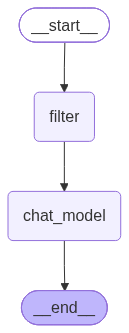

In [22]:
#6) Gerenciando conversas longas
#6.1) Removendo mensagens do estado com RemoveMessage
#Se você quer realmente alterar o estado (apagar mensagens antigas), use RemoveMessage.
#o node filter apaga tudo, exceto as 2 últimas mensagens
#o node chat_model responde usando o histórico já “limpo”


from langchain_core.messages import RemoveMessage
from langgraph.graph import MessagesState
from langgraph.graph import StateGraph, START, END

def filter_messages(state: MessagesState):
    # Deleta todas as mensagens exceto as 2 mais recentes
    delete = [RemoveMessage(id=m.id) for m in state["messages"][:-2]] # exclui tudo menos as 2 ultimas
    #delete = [RemoveMessage(id=m.id) for m in state["messages"][:-3]] # exclui tudo menos as 3 ultimas
    return {"messages": delete}

def chat_model_node(state: MessagesState):
    ai = groq_chat_streaming(
        [SystemMessage(content="Você é um tutor direto e prático.")] + state["messages"],
        max_completion_tokens=250,
    )
    return {"messages": [ai]}

builder = StateGraph(MessagesState)
builder.add_node("filter", filter_messages)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "filter")
builder.add_edge("filter", "chat_model")
builder.add_edge("chat_model", END)
graph_remove = builder.compile()

display(Image(graph_remove.get_graph().draw_mermaid_png()))




In [30]:
msgs = [
    AIMessage("Oi!", name="Eugenio_bot", id="1"),
    HumanMessage("Oi, sou o Eugenio JR.", name="Eugenio JR", id="2"),
    AIMessage("Me conta: qual parte do LangGraph tá mais confusa?", name="Eugenio_bot", id="3"),
    HumanMessage("Reducers e schema de estado. Principalmente quando tem paralelo.", name="Eugenio JR", id="4"),
]

out = graph_remove.invoke({"messages": msgs})
for m in out["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Name: Eugenio_bot

Me conta: qual parte do LangGraph tá mais confusa?
================================ Human Message =================================
Name: Eugenio JR

Reducers e schema de estado. Principalmente quando tem paralelo.
================================== Ai Message ==================================
Name: Eugenio-JR_bot

### Resumo rápido

| Conceito | O que é | Onde aparece |
|----------|---------|--------------|
| **Reducer** | Função pura que recebe o **estado atual** + **evento** e devolve o **novo estado** (e, opcionalmente, ações a serem disparadas). | Cada nó do grafo que tem lógica de atualização de estado. |
| **Schema de estado** | Descrição tipada (geralmente com **pydantic**, **TypedDict**, ou **dataclasses**) que define a forma exata do objeto de estado que os reducers vão ler/escrever. | Definido uma única vez (ou por sub‑grafo) e compartilhado por todos os nós que leem/escrevem

In [23]:
#CONTINUACAO
#6.2) Filtrando mensagens SEM alterar o estado
#Exemplo: mandar só a última mensagem do aluno.



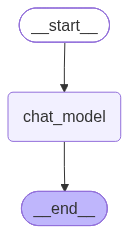

In [32]:
from langgraph.graph import MessagesState
from langgraph.graph import StateGraph, START, END

def chat_model_last_only(state: MessagesState):
    last = state["messages"][-1:]
    #last = state["messages"][:-1] 
    ai = groq_chat_streaming(
        [SystemMessage(content="Responda apenas ao último pedido do aluno, sem recontar tudo.")] + last,
        max_completion_tokens=220,
    )
    return {"messages": [ai]}

builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_last_only)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph_filter = builder.compile()

display(Image(graph_filter.get_graph().draw_mermaid_png()))

In [34]:
out = graph_filter.invoke({"messages": msgs})
msgs2 = msgs + [out["messages"][-1], HumanMessage("Agora me dá um exemplo curtinho de reducer com lista.", name="Eugenio JR")]
out2 = graph_filter.invoke({"messages": msgs2})
out2["messages"][-1].pretty_print()

================================== Ai Message ==================================
Name: Eugenio-JR_bot

```js
// reducer.js
const initialState = {
  items: []               // lista de itens
};

function listReducer(state = initialState, action) {
  switch (action.type) {
    case 'ADD_ITEM':
      return {
        ...state,
        items: [...state.items, action.payload]      // adiciona novo item
      };

    case


In [129]:
# 6.3) Trim (corte) por “tokens” com trim_messages
#um LLM do LangChain (que sabe contar tokens), ou
#ma função que conta tokens



In [36]:
from langchain_core.messages import(
    AIMessage,
    HumanMessage,
    SystemMessage,
    BaseMessage,
    trim_messages,
)
from langgraph.graph import MessagesState, StateGraph, START, END
from IPython.display import Image, display
def approx_token_counter(msgs):
    """Conta tokens de forma aproximada.

    - Recebe BaseMessage OU lista de BaseMessage
    - Faz uma conta simples baseada em palavras (didático, não perfeito)
    """
    if msgs is None:
        return 0
    if isinstance(msgs, BaseMessage):
        text = msgs.content or ""
    else:
        text = "\n".join([(m.content or "") for m in msgs])
    # heurística: ~1 token a cada ~0.75 palavra (bem aproximado)
    words = len(text.split())
    return int(words / 0.75) + 1

def chat_model_with_trim(state: MessagesState):
    trimmed = trim_messages(
        state["messages"],
        max_tokens=180,          # "budget" pequeno só pra enxergar o efeito
        strategy="last",
        token_counter=approx_token_counter,
        allow_partial=False,
        start_on="human",        # tenta garantir que começa em humano (bom pra muitos modelos)
        include_system=False,
    )

    ai = groq_chat_streaming(
        [SystemMessage(content="Você é um tutor conciso e prático.")] + trimmed,
        max_completion_tokens=220,
    )
    return {"messages": [ai]}

builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_with_trim)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph_trim = builder_trim.compile()

display(Image(graph_trim.get_graph().draw_mermaid_png()))



NameError: name 'builder_trim' is not defined

In [39]:
# Vamos criar um histórico maior

long_history = []
long_history.append(AIMessage("Oi Eugenio JR! Vamos revisar LangGraph.", name="Eugenio_Bot"))
for i in range(1, 9):
    long_history.append(HumanMessage(f"Pergunta {i}: me dá um exemplo prático de estado no LangGraph?", name="Eugenio JR"))
    long_history.append(AIMessage(f"Resposta {i}: (explicação longa simulada) ...", name="Eugenio_Bot"))

# Só pra visualizar o tamanho antes:
print("Mensagens antes:", len(long_history))
print("Tokens aprox antes:", approx_token_counter(long_history))

trimmed_preview = trim_messages(
    long_history,
    max_tokens=180,
    strategy="last",
    token_counter=approx_token_counter,
    allow_partial=False,
    start_on="human",
)

print("Mensagens depois do trim:", len(trimmed_preview))
print("Tokens aprox depois:", approx_token_counter(trimmed_preview))

# Agora chama o grafo que já faz trim + LLM
out3 = graph_trim.invoke({"messages": long_history + [HumanMessage("Agora resume reducers em 4 bullets.", name="Eugenio JR")]})
out3["messages"][-1].pretty_print()

Mensagens antes: 17
Tokens aprox antes: 190
Mensagens depois do trim: 14
Tokens aprox depois: 159
================================== Ai Message ==================================
Name: Eugenio-JR_bot

- **Função pura**: Recebe o estado atual e uma ação, e devolve um novo estado sem modificar o original.  
- **Imutabilidade**: Sempre cria/retorna um novo objeto de estado; assim o fluxo de dados permanece previsível e fácil de depurar.  
- **Composição**: Vários reducers podem ser combinados (ex.: `combineReducers`), permitindo dividir a lógica de atualização por domínio de dados.  
- **Tipagem de ação**: Cada reducer costuma tratar apenas um conjunto limitado de tipos de ação, ignorando as demais e retornando o estado inalterado.


NameError: name 'long_history' is not defined